[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/09-evaluation.ipynb)

# Evaluation and Error Analysis

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Report a headline metric with an interval, in the units of the decision.</li>
<li>Turn predictions into money using explicit, adjustable assumptions, and test their sensitivity.</li>
<li>Slice results to find groups where the model's probabilities cannot be trusted.</li>
<li>Read the worst mistakes to form hypotheses about missing information.</li>
</ul>
</div>

**Prerequisites:** <a href="../08-modelling/">Modelling</a>. **Dataset:** Online Retail II. **Time:** about 45 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

We have a champion model (the logistic regression) and a headline number. A headline number is where evaluation *starts*. A model that scores well on average can still fail for a specific group, mislead the business about money, or make mistakes that point to a missing piece of information. This page asks four questions in turn:

1. **How good is it, with honest uncertainty?**
2. **What does it mean in money, under stated assumptions?**
3. **For whom does it work, and for whom does it not?**
4. **What are its worst mistakes telling us?**

In [2]:
from mlp_data import models
from mlp_data.metrics import at_risk_report, bootstrap_interval, K

cleaned = retail.clean_retail(load_retail())
sp = retail.build_splits(cleaned.sales, cleaned.returns, features="full")
train, valid = sp.train, sp.valid

champion = models.make_logistic().fit(train[models.FEATURES], train["y"])
p = champion.predict_proba(valid[models.FEATURES])[:, 1]                              # probability of buying again
v = valid.assign(p=p, lapse=1 - valid["y"], value_at_risk=(1 - p) * valid["monetary"])  # value at risk = chance of lapsing x past-year spend
print(f"{len(v):,} validation customers; model trained on {len(train):,} training rows")

4,324 validation customers; model trained on 16,910 training rows


## 1. The headline, with uncertainty

We report the decision metrics from the baselines page, each with a 90% bootstrap interval. Revenue is ranked by value at risk, the rule that won there.

In [3]:
risk = v["value_at_risk"].to_numpy()
by_value = at_risk_report(v["y"], p, v["monetary"], risk=risk, probabilities=True)
by_prob = at_risk_report(v["y"], p, v["monetary"], probabilities=True)

headline = pd.DataFrame({
    "value": [by_prob["AUC"], by_value["precision@200"], by_value["revenue@200"], by_value["revenue@200 % of oracle"]],
    "90% interval": [bootstrap_interval(v["y"], p, v["monetary"], metric="AUC", n_boot=300)] +
                    [bootstrap_interval(v["y"], p, v["monetary"], metric=m, risk=risk, n_boot=300) for m in ["precision@200", "revenue@200", "revenue@200 % of oracle"]],
}, index=["AUC (ranking everyone)", "precision@200 (value-ranked)", "revenue@200 protected (pounds)", "revenue@200 % of the best possible"])
fmt = {"AUC (ranking everyone)": "{:.3f}", "precision@200 (value-ranked)": "{:.1%}", "revenue@200 protected (pounds)": "{:,.0f}", "revenue@200 % of the best possible": "{:.1%}"}
headline.apply(lambda r: pd.Series({"value": fmt[r.name].format(r["value"]), "90% interval": f"{fmt[r.name].format(r['90% interval'][0])} to {fmt[r.name].format(r['90% interval'][1])}"}), axis=1)

,value,90% interval
AUC (ranking everyone),0.796,0.784 to 0.809
precision@200 (value-ranked),43.5%,37.5% to 49.0%
revenue@200 protected (pounds),"571,074","447,211 to 709,333"
revenue@200 % of the best possible,62.9%,55.7% to 68.9%


## 2. How many calls are worth making?

Everything so far fixed the call budget at 200, which was an assumption. The **capture curve** shows what happens as the budget changes: for each number of calls K, the past-year revenue of the lapsers we reach, against what random calling, the earlier no-model rule, and a perfect oracle would reach.

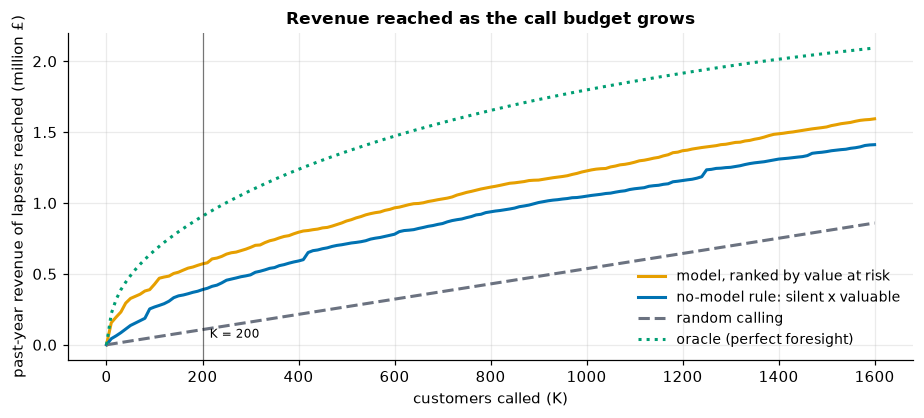

In [4]:
ks = np.arange(0, 1601, 10)
lapse_revenue = (v["lapse"] * v["monetary"]).to_numpy()
pct = lambda s: s.rank(pct=True)

def capture(risk_scores):
    order = np.argsort(-risk_scores, kind="stable")
    cum = np.concatenate([[0], np.cumsum(lapse_revenue[order])])
    return cum[ks]

curves = {
    "model, ranked by value at risk": capture(risk),
    "no-model rule: silent x valuable": capture((pct(v["recency_days"]) * pct(v["monetary"])).to_numpy()),
    "random calling": ks / len(v) * lapse_revenue.sum(),
    "oracle (perfect foresight)": np.concatenate([[0], np.cumsum(np.sort(lapse_revenue)[::-1])])[ks],
}
fig, ax = plt.subplots(figsize=(8.5, 3.9))
styles = [(style.ORANGE, "-"), (style.BLUE, "-"), (style.GREY, "--"), (style.GREEN, ":")]
for (name, y), (color, ls) in zip(curves.items(), styles):
    ax.plot(ks, y / 1e6, color=color, ls=ls, lw=2, label=name)
ax.axvline(K, color="black", lw=0.8, alpha=0.5); ax.text(K + 15, 0.05, "K = 200", fontsize=8)
ax.set(xlabel="customers called (K)", ylabel="past-year revenue of lapsers reached (million £)", title="Revenue reached as the call budget grows"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Reading the chart.** The model and the simple rule both rise far above random calling, and the model sits above the rule at every budget, with the widest *relative* gap at small budgets, where picking the right few giants matters most. Both are well below the oracle, which tells us the ceiling is high but that nobody can see the future. Returns diminish: the first hundred calls are worth much more than the next hundred.

## 3. From revenue to profit: the decision needs assumptions

Revenue reached is not profit. A call costs money, only some at-risk customers are won back, and revenue is not margin. These numbers belong to the business, not to the model, so we make them **explicit and adjustable**.

<div class="admonition warning">
<p class="admonition-title">These numbers are illustrative assumptions, not data</p>
<p>We assume a call costs £25, a call rescues 10% of the lapsers it reaches, and a rescued customer is worth 25% of their past-year revenue. Replace them with real figures before using the output for anything. The point of the exercise is to see <em>how the answer depends on them</em>.</p>
</div>

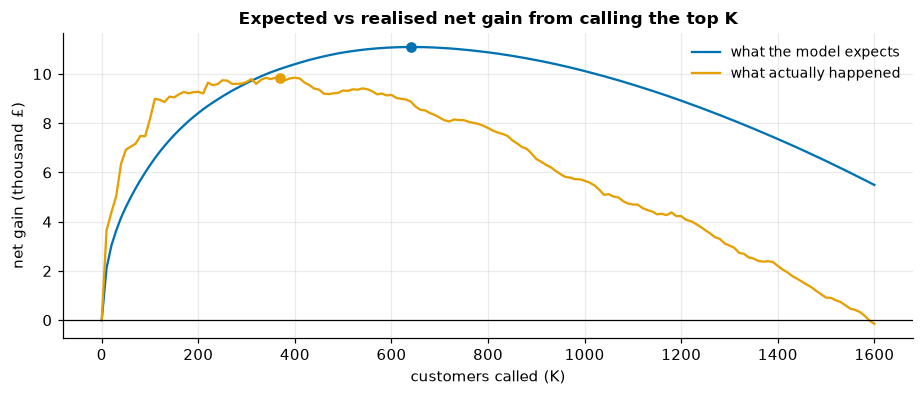

best K: model expects 640 calls (gain £11,098); in hindsight the best was 370 (gain £9,857); at K=200 realised gain is £9,277


In [5]:
def profit_curve(cost, save_rate, margin, ks=np.arange(0, 1601, 10)):
    """Expected net gain of calling the top-K by value at risk: what the model EXPECTS, and what actually HAPPENED."""
    order = np.argsort(-risk, kind="stable")
    value = v["monetary"].to_numpy()[order]
    expected = save_rate * margin * np.concatenate([[0], np.cumsum((1 - p[order]) * value)])[ks] - cost * ks     # uses the model's probabilities
    realised = save_rate * margin * np.concatenate([[0], np.cumsum(lapse_revenue[order])])[ks] - cost * ks       # uses what really happened
    return ks, expected, realised

ASSUME = dict(cost=25.0, save_rate=0.10, margin=0.25)
ks_, expected, realised = profit_curve(**ASSUME)
best_exp, best_real = ks_[expected.argmax()], ks_[realised.argmax()]

fig, ax = plt.subplots(figsize=(8.5, 3.7))
ax.plot(ks_, expected / 1e3, color=style.BLUE, label="what the model expects"); ax.plot(ks_, realised / 1e3, color=style.ORANGE, label="what actually happened")
ax.axhline(0, color="black", lw=0.8)
for k_, y_, c_ in [(best_exp, expected.max(), style.BLUE), (best_real, realised.max(), style.ORANGE)]:
    ax.plot([k_], [y_ / 1e3], "o", color=c_)
ax.set(xlabel="customers called (K)", ylabel="net gain (thousand £)", title="Expected vs realised net gain from calling the top K"); ax.legend()
plt.tight_layout(); plt.show()
print(f"best K: model expects {best_exp} calls (gain £{expected.max():,.0f}); in hindsight the best was {best_real} (gain £{realised.max():,.0f}); at K=200 realised gain is £{realised[ks_ == 200][0]:,.0f}")

**Reading the chart.** Under these assumptions the net gain rises quickly with the first calls, flattens, and falls once calls start reaching customers whose expected rescue value is below the £25 cost. The model's own optimum is about 640 calls, in hindsight about 370 would have been best, and our planned 200 calls realised roughly £9,300 (exact figures printed above). The most important feature is that **the curve is flat across a wide range**: anywhere from about 100 to 650 calls earns within about a tenth of the best, so *being in the right region matters more than the exact K*.

Notice that the two lines disagree, and **not in a simple direction**. For small budgets the model expects *less* than what happened, because a few very large customers it considered safe lapsed (we meet them in section 5). Beyond roughly 300 calls it expects *more* than happened, because it under-predicts how many customers return, so many of the extra calls go to people who would have bought anyway. Calibration error becomes money error, in both directions.

How much does this depend on the assumptions we invented? Sweep them.

In [6]:
grid = []
for cost in [10, 25, 50, 100]:
    for save in [0.05, 0.10, 0.20]:
        ks_g, ex, re = profit_curve(cost, save, 0.25)
        grid.append({"cost per call (£)": cost, "rescue rate": f"{save:.0%}", "best K (expected)": ks_g[ex.argmax()], "best K (hindsight)": ks_g[re.argmax()], "realised gain at the expected-best K (£)": f"{re[ex.argmax()]:,.0f}"})
pd.DataFrame(grid).set_index(["cost per call (£)", "rescue rate"])

best K (expected)  best K (hindsight) realised gain at the expected-best K (£)
cost per call (£) rescue rate                                                                                
10                5%                        1000                 600                                    5,333
                  10%                       1600                1570                                   23,852
                  20%                       1600                1600                                   63,704
25                5%                         120                 110                                    2,977
                  10%                        640                 370                                    8,881
                  20%                       1600                1570                                   39,704
50                5%                          20                  40                                    1,437
                  10%                        120                 110                                    5,953
                  20%                        640                 370                                   17,763
100               5%                          10                  10                                      948
                  10%                         20                  40                                    2,874
                  20%                        120                 110                                   11,907

**Reading the grid.** The best number of calls swings from about ten to the whole 1,600-call range of the grid (a value of 1600 means "at least that many"), depending on the cost per call and the rescue rate. **The assumptions, not the model, decide the budget.** The model supplies the *ranking*; the business must supply the economics. In our base case (£25, 10%) the realised gain at the model's recommended K is £8,881 against £9,857 at the hindsight best, about 90% of what was attainable. The honest deliverable is therefore the capture and profit curves plus this table, not one confident K.

## 4. For whom does it work? Slice the results

An average hides the places where a model is weak. We cut the validation customers into meaningful groups and compare, for each, the share who **really** returned with what the model **predicted** (on average), plus the ranking quality (AUC) inside the group. A group where actual and predicted differ a lot is one where the probabilities cannot be trusted.

In [7]:
def slice_table(groups):
    rows = []
    for name, labels in groups.items():
        for g, d in v.groupby(labels, observed=True):
            rows.append({"slice": name, "group": str(g), "customers": len(d), "actually returned": d["y"].mean(), "model predicted": d["p"].mean(),
                         "gap (pts)": (d["y"].mean() - d["p"].mean()) * 100, "AUC": roc_auc_score(d["y"], d["p"]) if d["y"].nunique() > 1 else np.nan})
    return pd.DataFrame(rows)

from sklearn.metrics import roc_auc_score
slices = slice_table({
    "orders in past year": pd.cut(v["frequency"], [1, 2, 4, 8, 10_000], right=False, labels=["1", "2-3", "4-7", "8+"]),
    "past-year spend":     pd.qcut(v["monetary"], 4, labels=["lowest quarter", "2nd", "3rd", "highest quarter"]),
    "country":             v["is_uk"].map({1: "UK", 0: "outside UK"}),
    "days since last order": pd.cut(v["recency_days"], [0, 30, 90, 180, 366], right=False, labels=["<30", "30-89", "90-179", "180+"]),
    "tenure (days since first order)": pd.cut(v["tenure_days"], [0, 90, 200, 366, 10_000], right=False, labels=["<90", "90-199", "200-365", "366+"]),
})
shown = slices.assign(**{"actually returned": slices["actually returned"].map("{:.1%}".format), "model predicted": slices["model predicted"].map("{:.1%}".format),
                         "gap (pts)": slices["gap (pts)"].map("{:+.1f}".format), "AUC": slices["AUC"].map("{:.3f}".format)})
shown.set_index(["slice", "group"])

customers actually returned model predicted gap (pts)    AUC
slice                           group                                                                        
orders in past year             1                     1562             15.7%           13.1%      +2.6  0.617
                                2-3                   1340             30.2%           23.6%      +6.6  0.663
                                4-7                    891             54.3%           45.4%      +8.9  0.668
                                8+                     531             84.6%           79.2%      +5.3  0.776
past-year spend                 lowest quarter        1081             13.8%           12.2%      +1.6  0.597
                                2nd                   1081             25.3%           18.9%      +6.3  0.652
                                3rd                   1081             37.2%           31.7%      +5.5  0.659
                                highest quarter       1081             70.2%           61.8%      +8.4  0.781
country                         UK                    3957             36.1%           30.6%      +5.5  0.795
                                outside UK             367             42.5%           37.2%      +5.3  0.803
days since last order           <30                   1043             65.5%           56.7%      +8.8  0.793
                                30-89                  914             46.0%           35.5%     +10.4  0.743
                                90-179                 700             32.0%           25.2%      +6.8  0.656
                                180+                  1667             15.4%           15.3%      +0.1  0.627
tenure (days since first order) <90                    381             40.2%           22.2%     +17.9  0.724
                                90-199                 477             24.3%           23.1%      +1.3  0.760
                                200-365               1367             24.3%           25.7%      -1.4  0.800
                                366+                  2099             46.8%           38.1%      +8.7  0.796

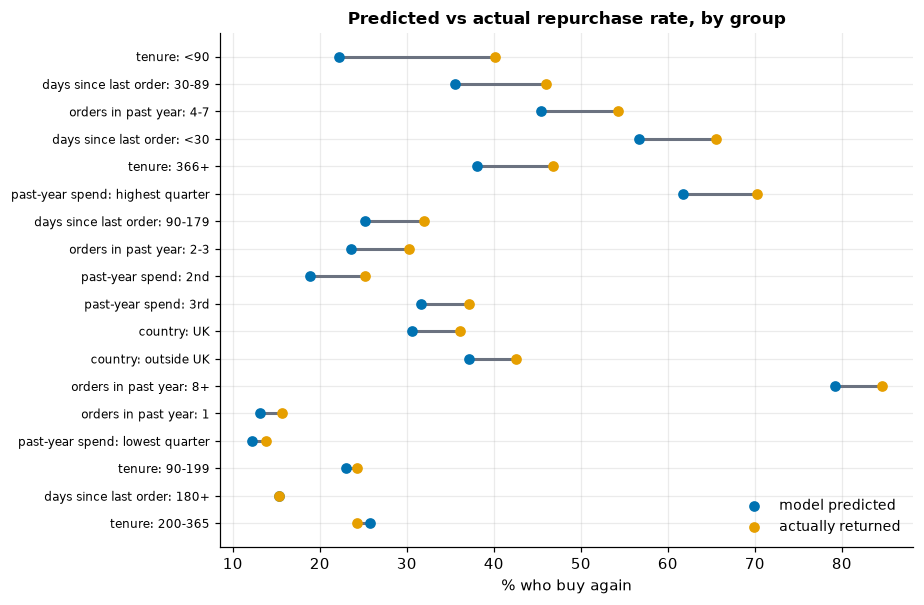

In [8]:
ordered = slices.assign(label=slices["slice"].str.split(" \\(").str[0] + ": " + slices["group"]).sort_values("gap (pts)")
fig, ax = plt.subplots(figsize=(8.5, 5.6))
y = np.arange(len(ordered))
ax.hlines(y, ordered["model predicted"] * 100, ordered["actually returned"] * 100, color=style.GREY, lw=2)
ax.scatter(ordered["model predicted"] * 100, y, color=style.BLUE, zorder=3, label="model predicted")
ax.scatter(ordered["actually returned"] * 100, y, color=style.ORANGE, zorder=3, label="actually returned")
ax.set_yticks(y, ordered["label"], fontsize=8); ax.set(xlabel="% who buy again", title="Predicted vs actual repurchase rate, by group"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Reading the table and the chart.** Two separate things stand out.

1. **A level shift almost everywhere.** In nearly every group more customers returned than the model predicted (the orange dot sits to the right of the blue one), typically by five to nine points; overall the model predicts about 31% against 37% actual. The groups with essentially no gap are the long-silent (180+ days) and the middle-tenure customers. This is mostly a *calibration* problem rather than a ranking problem: the AUCs are healthy, but the probabilities run low across the board. It is not specific to any kind of customer: UK and non-UK customers show the same gap (about 5.5 points each), so there is **no sign of a country-specific failure**.
2. **One segment is badly off: new customers.** Customers whose first order was under 90 days ago actually returned about 40% of the time, and the model said 22%. That is an 18-point miss on 381 customers, three times the typical gap.

Is the new-customer miss a flaw in the model, or did something change? Compare the same group in the training period and in validation.

In [9]:
new_train, new_valid = train["tenure_days"] < 90, valid["tenure_days"] < 90
pd.DataFrame({
    "share of customers": [new_train.mean(), new_valid.mean()],
    "actually returned": [train.loc[new_train, "y"].mean(), valid.loc[new_valid, "y"].mean()],
    "model predicted": [champion.predict_proba(train.loc[new_train, models.FEATURES])[:, 1].mean(), p[new_valid.to_numpy()].mean()],
}, index=["training snapshots (Dec to Mar)", "validation snapshot (Jun)"]).map("{:.1%}".format)

,share of customers,actually returned,model predicted
training snapshots (Dec to Mar),14.3%,24.0%,21.9%
validation snapshot (Jun),8.8%,40.2%,22.2%


In training, new customers came back about a quarter of the time, and the model learned exactly that. In the validation period the same kind of customer came back about 40% of the time. **The model is not mis-fitted; behaviour changed.** Newly acquired customers in early summer reorder far more often than newly acquired customers in winter. The data cannot tell us *why* (running up to the autumn peak is one candidate), and with only one winter and one summer in view we should not pretend otherwise. This is our first concrete evidence of **drift**, a model faithfully describing a world that has moved on. We return to it when we monitor.

## 5. What are the worst mistakes telling us?

Averages and slices say *where* the model is off. Reading individual cases says *why*. Two kinds of mistake matter most to the business.

In [10]:
misses = v[(v["p"] >= 0.7) & (v["lapse"] == 1)].sort_values("monetary", ascending=False)
share_of_lapse_revenue = misses["monetary"].sum() / (v["lapse"] * v["monetary"]).sum()
print(f"Confident misses: {len(misses)} customers the model gave at least a 70% chance of returning, who lapsed. They hold {share_of_lapse_revenue:.1%} of all lapser revenue.")
print(f"Typical (median) miss: {misses['frequency'].median():.0f} orders in the year, an order every {misses['avg_gap_days'].median():.0f} days; all customers: {v['frequency'].median():.0f} orders.\n")
misses[["customer_id", "p", "frequency", "recency_days", "avg_gap_days", "monetary"]].head(8).rename(columns={"p": "predicted to return", "frequency": "orders", "recency_days": "days silent", "avg_gap_days": "usual gap (days)", "monetary": "past-year spend"}).round(2)

Confident misses: 37 customers the model gave at least a 70% chance of returning, who lapsed. They hold 9.9% of all lapser revenue.
Typical (median) miss: 11 orders in the year, an order every 32 days; all customers: 2 orders.



,customer_id,predicted to return,orders,days silent,usual gap (days),past-year spend
521,13093,0.93,38,83.49,7.32,"40,421.92"
4009,17850,0.91,94,180.36,1.65,"24,738.47"
4128,18008,0.89,14,11.29,26.63,"18,257.36"
2788,16191,0.83,17,70.63,17.75,"12,759.83"
851,13564,0.75,22,162.30,9.48,"10,601.65"
1888,14952,0.91,16,14.64,21.32,"8,364.27"
3759,17504,0.90,14,14.46,22.62,"7,601.43"
686,13324,0.90,14,11.41,25.46,"6,840.35"


In [11]:
surprises = v[(v["p"] <= 0.2) & (v["y"] == 1)]
top200 = v.sort_values("value_at_risk", ascending=False).head(K)
print(f"Surprise returners: {len(surprises)} customers given 20% or less who came back; median spend {surprises['monetary'].median():,.0f}, median orders {surprises['frequency'].median():.0f}.")
print(f"The 200 we would call: median spend {top200['monetary'].median():,.0f}, median orders {top200['frequency'].median():.0f}, median predicted return {top200['p'].median():.0%}, and {top200['lapse'].mean():.0%} of them really did lapse.")

Surprise returners: 325 customers given 20% or less who came back; median spend 321, median orders 1.
The 200 we would call: median spend 4,699, median orders 5, median predicted return 49%, and 44% of them really did lapse.


In [12]:
challenger = models.make_boosting().fit(train[models.FEATURES], train["y"])
p_challenger = challenger.predict_proba(valid[models.FEATURES])[:, 1]
is_miss = ((v["p"] >= 0.7) & (v["lapse"] == 1)).to_numpy()
print(f"the boosted challenger also gives {int((p_challenger[is_miss] >= 0.7).sum())} of these {is_miss.sum()} customers at least 70%; "
      f"its average is {p_challenger[is_miss].mean():.2f} against the champion's {v.loc[is_miss, 'p'].mean():.2f}")

the boosted challenger also gives 29 of these 37 customers at least 70%; its average is 0.75 against the champion's 0.79


**The confident misses.** Thirty-seven customers the model was at least 70% sure would return did not. They hold about a tenth of all the revenue that lapsed, which is why they matter. They are not obscure: typically about eleven orders in the year, one every month or so, against a population median of two. The most striking, customer 17850, placed 94 orders in the year (about one every two days), had then been silent for six months, and was still scored 91% likely to return. These are **regular customers who suddenly stopped**.

Two lessons. First, a model built from recency, frequency and spend cannot know *why* a loyal customer vanished (a competitor, a dispute, a closed business). Second, **swapping the algorithm does not fix it**: the challenger scores most of the same customers just as confidently. When two quite different models make the same mistake, the missing piece is *information*, not model power. (One cheap hypothesis for the next page: our champion caps the "overdue" ratio at 50, which treats a customer silent for 50 times their usual gap the same as one silent for 100 times.)

**The surprise returners.** The 322 customers the model gave 20% or less who came back were mostly one-order customers spending a few hundred pounds. They are the opposite kind of error: numerous but cheap, so they cost little revenue.

**The calls we would make.** The 200 customers picked by value at risk have a median past-year spend of about £4,700 and a median predicted return chance of about one half, and **44% of them really lapsed**. So more than half of the calls reach customers who would have bought anyway. Ranking by value buys revenue protection at the price of precision; whether that is a good trade depends on what a call costs, which is exactly what the profit analysis priced in.

## What we would try next

These are **hypotheses from the evidence**, not conclusions:

| Finding | Hypothesis to test |
|---|---|
| Probabilities low everywhere | the training period is not typical; recalibrate on a more recent period, or monitor and refresh regularly |
| New customers badly under-predicted | their behaviour is seasonal; needs more than one winter and one summer of history to learn |
| Loyal customers who stop | a feature that is not capped, e.g. the full "overdue" ratio, may sharpen the signal; otherwise new information is needed |
| Budget depends on assumptions | agree the economics with the business before fixing K |

## Check yourself

<details class="question">
<summary>1. The AUC inside several groups is lower than the overall AUC. Is the model worse for each of them?</summary>

Not necessarily. AUC measures how well the score *separates* returners from lapsers. Inside a narrow slice (say, customers who all ordered once) the scores and outcomes are less spread out, so there is less to separate. The overall AUC benefits from the easy contrasts *between* groups (a heavy buyer versus a one-off). Compare each slice's calibration gap and look at who the model is for, not just a smaller AUC number.

</details>

<details class="question">
<summary>2. In the profit chart, is the model's expected gain above or below what really happened? Why does it matter?</summary>

It depends on the budget: below roughly 300 calls the model expects less than happened (a few big, wrongly-trusted customers lapsed), and above that it expects more (it under-predicts returns). The expected-gain calculation multiplies the model's probabilities by money, so any calibration error becomes a **money error**, and it need not point in one direction. A decision made on expected value is only as good as the probabilities feeding it.

</details>

<details class="question">
<summary>3. Why do we report the sensitivity table instead of just the 'best K' for our assumed numbers?</summary>

Because the assumed cost, rescue rate and margin are guesses. If the optimal K swings widely as they change, the recommendation is fragile and the business must pin those numbers down; if it barely moves, we can act with confidence. Showing the dependence is more honest than a single confident number.

</details>

## Exercise

<details class="question">
<summary>A call costs £100, not £25. Predict what happens to the best K and to the realised gain, then check it with <code>profit_curve</code>.</summary>

```python
for cost in (25, 100):
    ks_c, ex, re = profit_curve(cost=cost, save_rate=0.10, margin=0.25)
    print(f"cost £{cost}: expected-best K = {ks_c[ex.argmax()]}, realised gain there = £{re[ex.argmax()]:,.0f}")
```

At £25 per call the model's best K is about 640 (realised gain about £8,900); at £100 it falls to about 20 (realised gain about £2,900). **The economics, not the model, changed the answer**: when calls are expensive only the very highest-value customers are worth phoning. This is why the budget is a business decision, and why we show the sweep instead of a single number.

</details>

## Recap

- A headline metric is the start. Report it with an interval, and in the units of the decision (here, revenue protected within a call budget).
- A **capture curve** shows how value grows with the budget and where returns diminish.
- To turn predictions into money you need assumptions. Make them explicit, label them as assumptions, and **sweep them**: a fragile recommendation should look fragile.
- **Slice** the results. Averages hide groups where the model is badly calibrated; those are where trust breaks down.
- Read the worst mistakes. They suggest what information is missing, not just that the model is imperfect.

**Next:** *Tuning and experiment tracking*, where we try to improve the model systematically and keep a record that makes every result reproducible.